# EDA Project: Diamonds
### Python for AI, Month 1 project

**EDA** means Exploratory Data Analysis. Before any model, we first understand the data.

**Our data:** 53,940 diamonds with their weight, quality grades, size and price.

**Our big question:** *What makes a diamond expensive?*

**Our questions:**
1. Is **carat** (weight) the main thing that decides the price?
2. Do **cut**, **color** and **clarity** make the price higher?
3. Are there **outliers** in the price? Are they mistakes?
4. Is one `volume` column enough instead of `x`, `y` and `z`?

We follow the 5 steps from class: Load, Inspect, Clean, Explore, Conclude.

## Step 1: Load

First we import the libraries and read `diamonds.csv`. If the file is not there, it is downloaded one time and saved.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')

In [2]:
try:
    df = pd.read_csv('diamonds.csv')
except FileNotFoundError:
    sns.load_dataset('diamonds').to_csv("diamonds.csv", index=False)
    df = pd.read_csv('diamonds.csv')

In [3]:
df

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75
...,...,...,...,...,...,...,...,...,...,...
53935,0.72,Ideal,D,SI1,60.8,57.0,2757,5.75,5.76,3.50
53936,0.72,Good,D,SI1,63.1,55.0,2757,5.69,5.75,3.61
53937,0.70,Very Good,D,SI1,62.8,60.0,2757,5.66,5.68,3.56
53938,0.86,Premium,H,SI2,61.0,58.0,2757,6.15,6.12,3.74


**What each column means** (copied from the class file):

| **Diamonds** | `pd.read_csv("diamonds.csv")` | 53,940 diamonds and their price | What makes a diamond expensive? |

- **Diamonds:** `carat` (weight), `cut` (quality of the cutting: Fair → Ideal), `color` (D = best → J), `clarity` (how clean inside: I1 = worst → IF = best), `price` (in dollars), `x`, `y`, `z` (length, width, depth in mm), `depth` and `table` (shape measurements in %). Big dataset: charts can be slow.

## Step 2: Inspect

We run the usual inspect lines: `shape`, `describe`, `info`, `isna` and `value_counts`.

In [4]:
df.shape

(53940, 10)

In [5]:
df.describe()

,carat,depth,table,price,x,y,z
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,0.797940,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,0.474011,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53940 non-null  float64
 1   cut      53940 non-null  str    
 2   color    53940 non-null  str    
 3   clarity  53940 non-null  str    
 4   depth    53940 non-null  float64
 5   table    53940 non-null  float64
 6   price    53940 non-null  int64  
 7   x        53940 non-null  float64
 8   y        53940 non-null  float64
 9   z        53940 non-null  float64
dtypes: float64(6), int64(1), str(3)
memory usage: 4.1 MB


In [7]:
df.isna().sum()

carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64

In [8]:

print(df['cut'].value_counts())


cut
Ideal        21551
Premium      13791
Very Good    12082
Good          4906
Fair          1610
Name: count, dtype: int64


In [9]:
print(df['clarity'].value_counts())


clarity
SI1     13065
VS2     12258
SI2      9194
VS1      8171
VVS2     5066
VVS1     3655
IF       1790
I1        741
Name: count, dtype: int64


In [10]:
df['carat'].max()

np.float64(5.01)

In [11]:
df['carat'].mean()

np.float64(0.7979397478680015)

In [12]:
df['color'].value_counts()


color
G    11292
E     9797
F     9542
H     8304
D     6775
I     5422
J     2808
Name: count, dtype: int64

In [13]:
df.isna().sum()

carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64

no null values

**What I noticed while inspecting:**
- 53,940 rows and 10 columns. No missing values anywhere, so we do not need `fillna`.
- `cut`, `color` and `clarity` are text columns. We will turn them into numbers.
- In `describe`, the minimum of `x` is 0. A diamond cannot have 0 mm size, so these rows are wrong.
- `y` goes up to 58.9 and `z` goes up to 31.8. For a normal diamond this is too big. These look like typing mistakes.

## Step 3: Clean

For each problem I write the fix and the reason.

now we have to merge x,y,z as volume to make it better

In [14]:
print(((df['x'] == 0) | (df['y'] == 0) | (df['z'] == 0)).sum()) 

df = df[(df['x'] > 0) & (df['y'] > 0) & (df['z'] > 0)]
df = df[(df['y'] < 20) & (df['z'] < 20)]
df = df.reset_index(drop=True)
df["volume"] = df["x"] * df["y"] * df["z"]

20


**What the cell above did and why:**
- 20 rows had `x`, `y` or `z` equal to 0. A real diamond cannot have 0 size, so I removed them.
- 3 more rows had very big `y` or `z` (58.9 and 31.8 mm) for small diamonds. Those are mistakes, so I removed them too. This is why the rows went from 53,940 to 53,917.
- `reset_index` puts the row numbers back in order after removing rows.
- `volume = x * y * z`. The three sizes together tell how big the diamond is, and one column is easier to use than three.

set string values columns into numeric form
cut: Fair=1, Good=2, Very Good=3, Premium=4, Ideal=5
color: J=1, I=2, H=3, G=4, F=5, E=6, D=7
clarity: I1=1, SI2=2, SI1=3, VS2=4, VS1=5, VVS2=6, VVS1=7, IF=8

In [15]:
df['cut'] = np.where(df['cut'] == 'Fair', 1,
                 np.where(df['cut'] == 'Good', 2,
                 np.where(df['cut'] == 'Very Good', 3,
                 np.where(df['cut'] == 'Premium', 4,
                 np.where(df['cut'] == 'Ideal', 5, np.nan)))))

In [16]:
df['color'] = np.where(df['color'] == 'J', 1,
                np.where(df['color'] == 'I', 2,
                 np.where(df['color'] == 'H', 3,
                 np.where(df['color'] == 'G', 4,
                 np.where(df['color'] == 'F', 5,
                 np.where(df['color'] == 'E', 6,  
                 np.where(df['color'] == 'D', 7,       
                          np.nan)))))))

In [17]:
df['clarity'] = np.where(df['clarity'] == 'I1',1,
                np.where(df['clarity'] == 'SI2',2,
                 np.where(df['clarity'] == 'SI1' ,3,
                 np.where(df['clarity'] == 'VS2',4,
                 np.where(df['clarity'] == 'VS1',5,
                 np.where(df['clarity'] == 'VVS2',6,  
                 np.where(df['clarity'] == 'VVS1',7,
                 np.where(df['clarity'] == 'IF',8,     
                          np.nan))))))))

**Why I made them numbers:** the correlation heatmap works only with numbers. I gave the numbers in order, so a bigger number always means better quality (Fair = 1 is the worst cut, Ideal = 5 is the best). `np.where` is the same command we used for `age_group` in the Titanic class.

after converting we have extra columns now we have to remove some extras columns like x,y,z, cut,clarity,color 

In [18]:
df.head(2)

,carat,cut,color,clarity,depth,table,price,x,y,z,volume
0,0.23,5.0,6.0,2.0,61.5,55.0,326,3.95,3.98,2.43,38.202030
1,0.21,4.0,6.0,3.0,59.8,61.0,326,3.89,3.84,2.31,34.505856


In [19]:
df = df.drop(columns=['x','y','z'])

**Why I dropped `x`, `y`, `z`:** their information is now inside `volume`, so keeping them repeats the same thing (like dropping `class` and `who` in Titanic).

In [20]:
# after drop we have all numeric data and add new colums
df.head()

,carat,cut,color,clarity,depth,table,price,volume
0,0.23,5.0,6.0,2.0,61.5,55.0,326,38.202030
1,0.21,4.0,6.0,3.0,59.8,61.0,326,34.505856
2,0.23,2.0,6.0,5.0,56.9,65.0,327,38.076885
3,0.29,4.0,2.0,4.0,62.4,58.0,334,46.724580
4,0.31,2.0,1.0,2.0,63.3,58.0,335,51.917250


In [21]:
df.shape  

(53917, 8)

In [22]:
print(df.duplicated().sum())


145


In [23]:
df = df.drop_duplicates()

In [24]:
df.shape

(53772, 8)

**Why I dropped duplicates:** 145 rows were exact copies of other rows. A copy counts the same diamond two times, so I removed them with `drop_duplicates`. Now we have 53,772 rows and 8 columns, all numbers.

## Step 4: Explore

### Volume: spread and outliers

In [25]:
df['volume'].describe()

count    53772.000000
mean       129.777480
std         76.360280
min         31.707984
25%         65.208338
50%        114.852720
75%        170.834047
max        790.133208
Name: volume, dtype: float64

<Axes: xlabel='volume'>

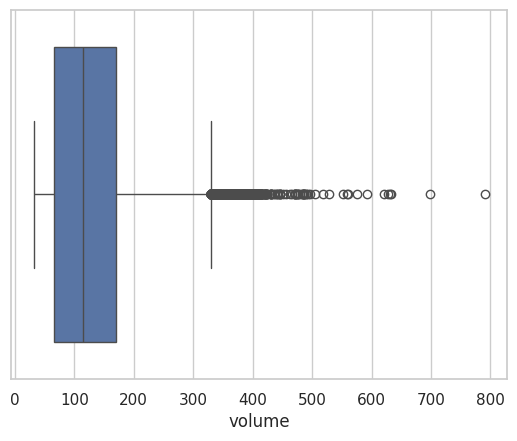

In [26]:
sns.boxplot(data=df, x='volume')

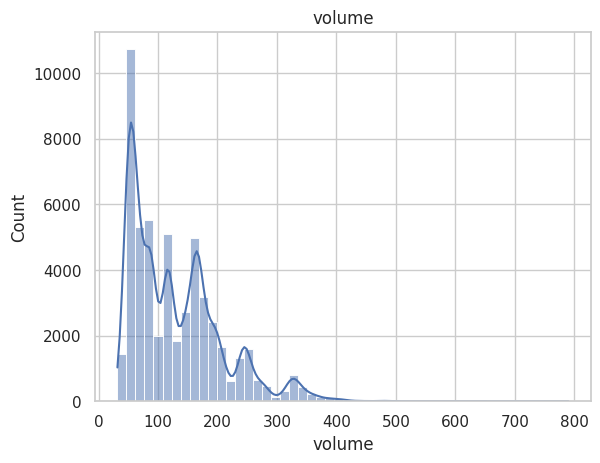

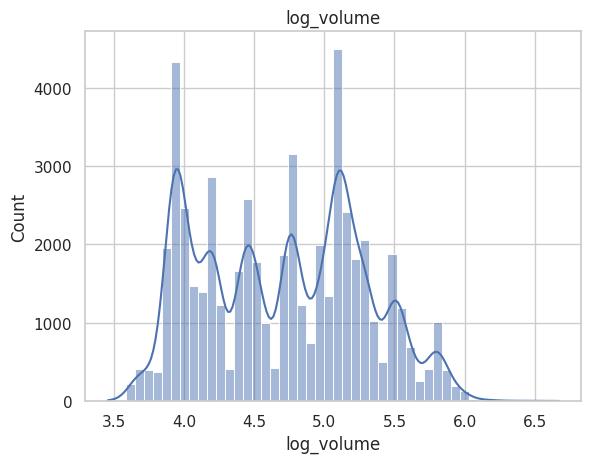

In [27]:
df["log_volume"] = np.log(df["volume"])

sns.histplot(df["volume"], bins=50,kde=True)
plt.title("volume")
plt.show()
sns.histplot(df["log_volume"], bins=50, kde=True)
plt.title("log_volume")
plt.show()

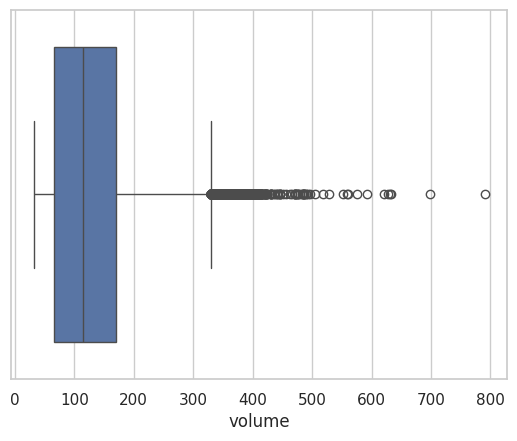

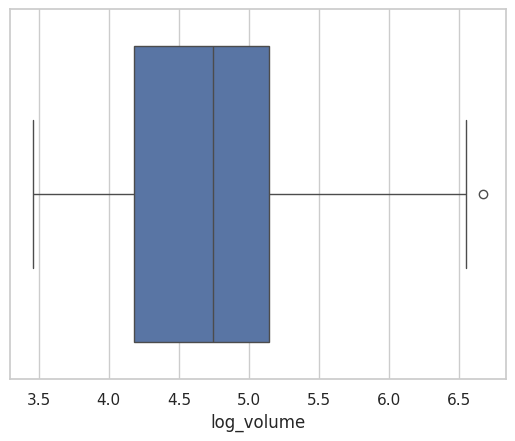

count    53772.000000
mean         4.700078
std          0.578359
min          3.456569
25%          4.177587
50%          4.743651
75%          5.140693
max          6.672202
Name: log_volume, dtype: float64

In [28]:
sns.boxplot(data=df, x='volume')
plt.show()
sns.boxplot(data=df, x='log_volume')
plt.show()
df['log_volume'].describe()

**What I see:** the volume box plot has many dots on the right side (1,312 outliers by the IQR rule). These are big diamonds, not mistakes. We already removed the real mistakes (zero and impossible sizes), so I **keep** these.

The histogram has a long tail to the right: most diamonds are small and a few are very big. So I made `log_volume` with `np.log`. A log pulls the long tail closer. After it the histogram looks more balanced and the box plot has almost no dots (only 1).

### Price: outliers

In [29]:
q1 = df['price'].quantile(0.25)
q3 = df['price'].quantile(0.75)
iqr = q3 - q1
high = q3 + 1.5 * iqr
high

outliers = df[df['price']>high]
len(outliers)

3519

In [30]:
print("Upper fence:", round(high))
print("Outliers:", len(outliers), "out of", len(df))
print("Percent of outliers:", round(len(outliers) / len(df) * 100, 1), "%")
print("Average carat of outliers:", round(outliers['carat'].mean(), 2), " Average carat of all:", round(df['carat'].mean(), 2))

Upper fence: 11884
Outliers: 3519 out of 53772
Percent of outliers: 6.5 %
Average carat of outliers: 1.85  Average carat of all: 0.8


**What I see:** any price above 11,884 is an outlier by the IQR rule. That is 3,519 diamonds, about 6.5% of the data. Their average weight is about 1.85 carat while the average of all diamonds is 0.80 carat. So they are just big, rare and expensive diamonds. They are real, not mistakes, so I **keep** them.

<Axes: xlabel='price'>

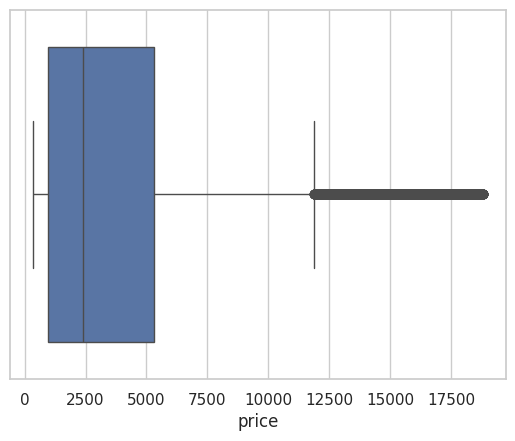

In [31]:
sns.boxplot(data=df,x='price')

In [32]:
df["log_price"] = np.log(df["price"])

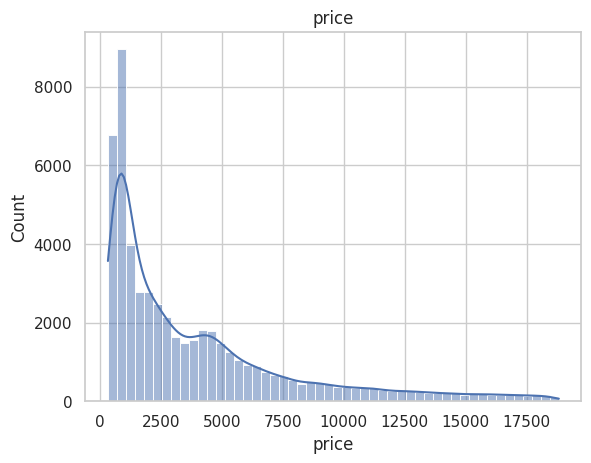

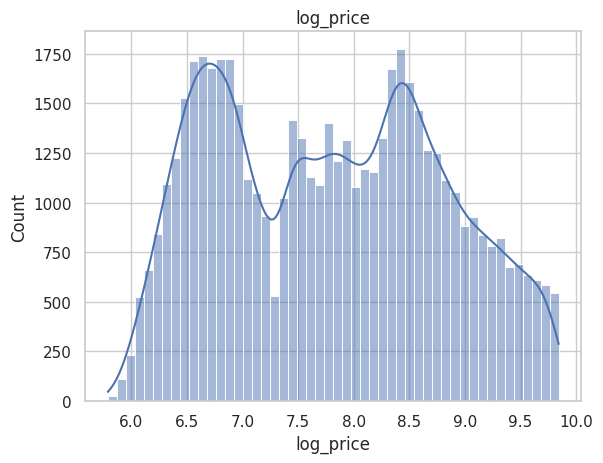

In [33]:
sns.histplot(df["price"], bins=50,kde=True)
plt.title("price")
plt.show()
sns.histplot(df["log_price"], bins=50, kde=True)
plt.title("log_price")
plt.show()

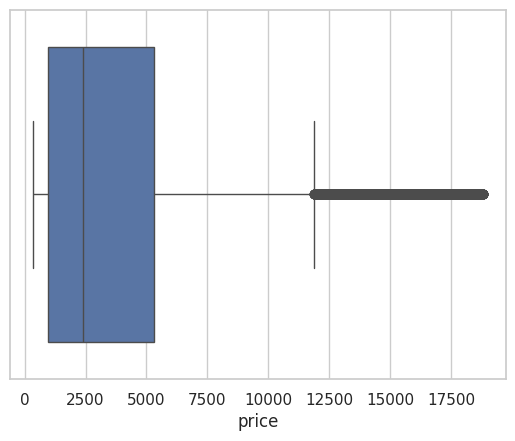

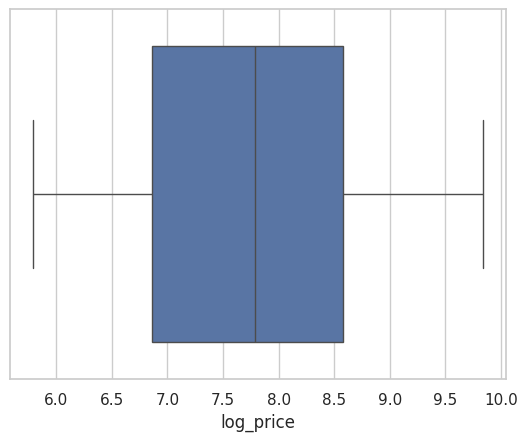

count    53772.000000
mean      3931.137321
std       3985.853004
min        326.000000
25%        951.000000
50%       2401.000000
75%       5324.000000
max      18823.000000
Name: price, dtype: float64

In [34]:
sns.boxplot(data=df, x='price')
plt.show()
sns.boxplot(data=df, x='log_price')
plt.show()
df['price'].describe()

In [35]:
df['log_price'].describe()

count    53772.000000
mean         7.786735
std          1.014324
min          5.786897
25%          6.857514
50%          7.783641
75%          8.579980
max          9.842835
Name: log_price, dtype: float64

**What I see:** the average price is 3,931 but the middle (median) is 2,401. The average is pulled up by the expensive diamonds. After `np.log` (`log_price`) the histogram is more balanced and the box plot has no outlier dots.

### Carat

<Axes: xlabel='carat'>

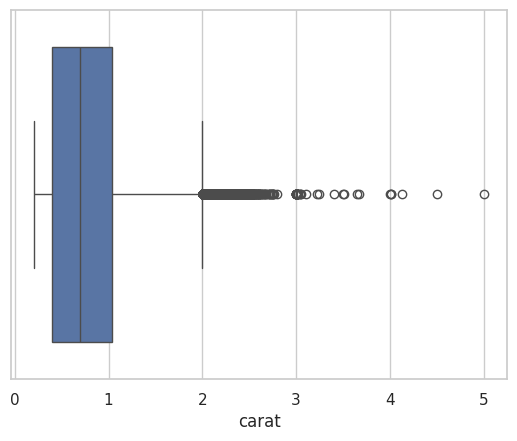

In [36]:
sns.boxplot(data=df, x='carat')

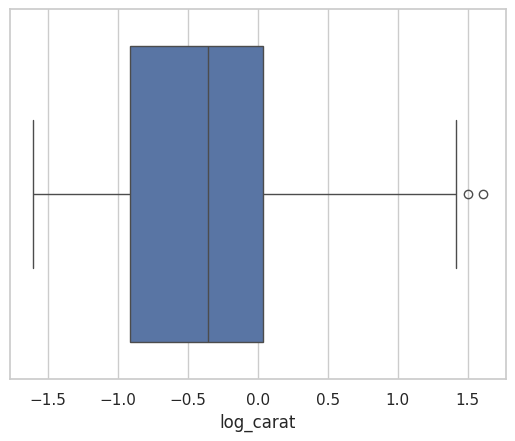

In [37]:
df["log_carat"] = np.log(df["carat"])
sns.boxplot(data=df,x='log_carat')
plt.show()

**What I see:** `carat` also has dots on the right (1,867 big diamonds). They are real, so I keep them. I made `log_carat` for the same reason as before, and its box plot has almost no dots (only 2).

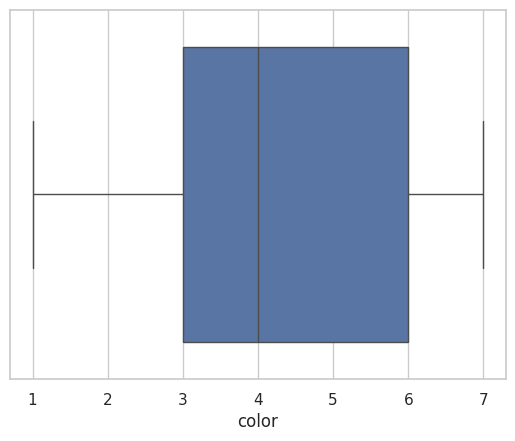

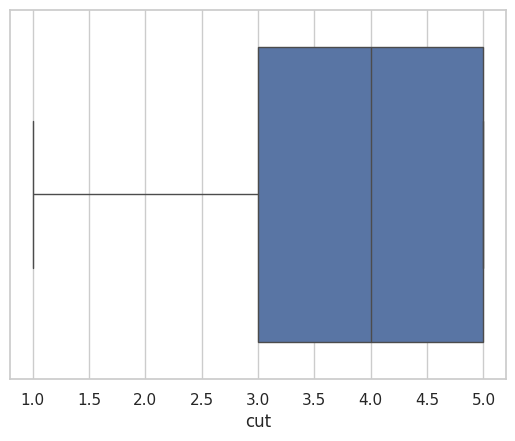

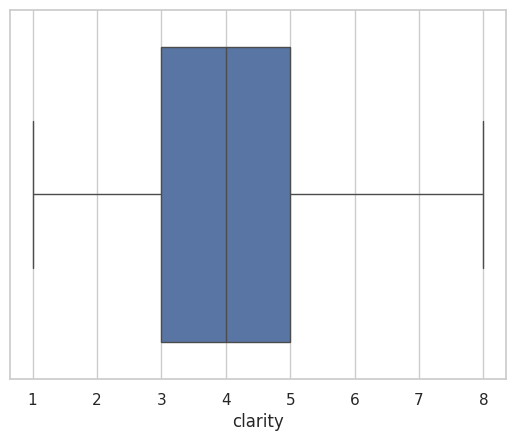

In [38]:
sns.boxplot(data=df,x='color')
plt.show()
sns.boxplot(data=df,x='cut')
plt.show()
sns.boxplot(data=df,x='clarity')
plt.show()


**Note:** `cut`, `color` and `clarity` are now grades (1 to 5, 1 to 7, 1 to 8), so these box plots only show the range of the grades. There is no useful outlier here. The real comparison with price comes in the findings.

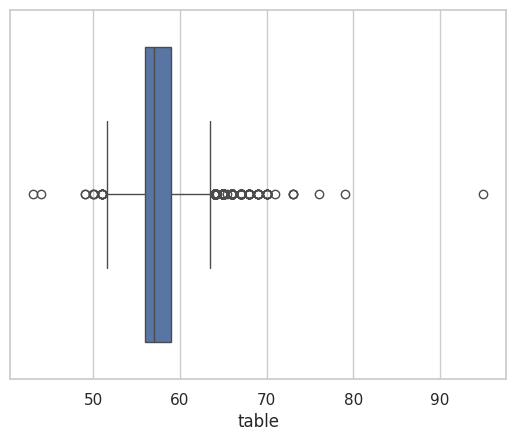

In [39]:
sns.boxplot(data=df,x='table')
plt.show()

**What I see:** `table` has a few dots on both sides, but its values (43 to 95) are measurements of real diamonds, so I keep them.

In [40]:
df.columns

Index(['carat', 'cut', 'color', 'clarity', 'depth', 'table', 'price', 'volume',
       'log_volume', 'log_price', 'log_carat'],
      dtype='str')

### Relations: the correlation heatmap

First heatmap uses the normal columns. The second one uses the log columns.

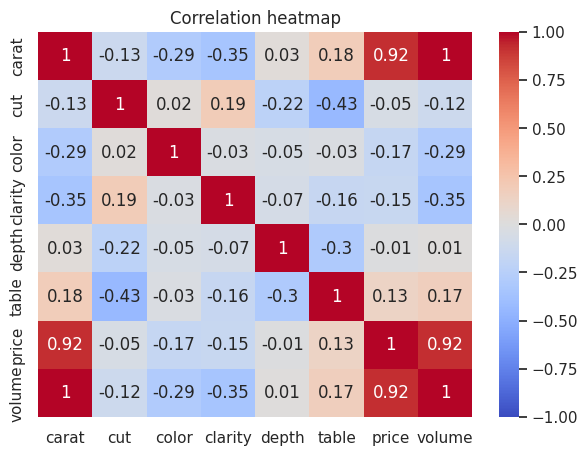

In [41]:
cols=['carat', 'cut', 'color', 'clarity', 'depth', 'table', 'price', 'volume',]

plt.figure(figsize=(7,5))
sns.heatmap(df[cols].corr().round(2), annot=True, cmap='coolwarm',vmin=-1,vmax=1)
plt.title("Correlation heatmap")
plt.show()

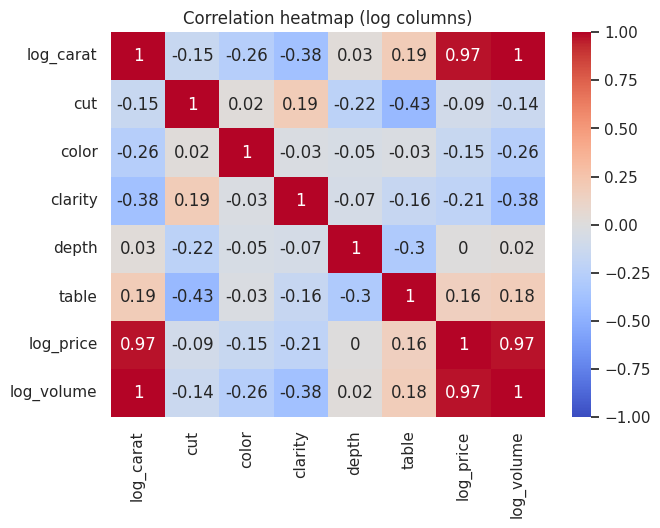

In [42]:
cols=['log_carat', 'cut', 'color', 'clarity', 'depth', 'table', 'log_price', 'log_volume',]

plt.figure(figsize=(7,5))
sns.heatmap(df[cols].corr().round(2), annot=True, cmap='coolwarm',vmin=-1,vmax=1)
plt.title("Correlation heatmap (log columns)")
plt.show()

In [43]:
normal_cols = ['carat', 'cut', 'color', 'clarity', 'depth', 'table', 'price', 'volume']
print(df[normal_cols].corr()['price'].round(2).sort_values())
print()
print(df[cols].corr()['log_price'].round(2).sort_values())

color     -0.17
clarity   -0.15
cut       -0.05
depth     -0.01
table      0.13
carat      0.92
volume     0.92
price      1.00
Name: price, dtype: float64

clarity      -0.21
color        -0.15
cut          -0.09
depth         0.00
table         0.16
log_carat     0.97
log_volume    0.97
log_price     1.00
Name: log_price, dtype: float64


**What I see in the heatmaps:**
- `carat` and `volume` are the most related to price (0.92 on normal columns). After the log it goes up to 0.97, so the relation is stronger on the log scale.
- `cut`, `color`, `clarity` have small **negative** numbers with price (about -0.05, -0.17, -0.15). It looks strange that better quality is related to a lower price. I check this in the findings.
- `depth` is almost 0 and `table` is small, so they do not help much.
- `carat` and `volume` are almost the same thing (they are close to 1 with each other), so we do not need both. This answers question 4.

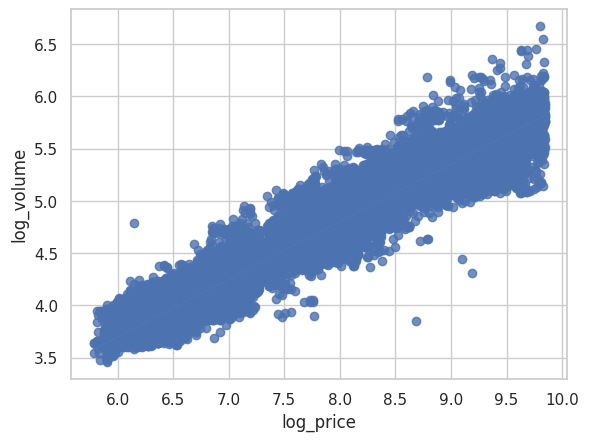

In [44]:
sns.regplot(data=df,x='log_price',y='log_volume')
plt.show()

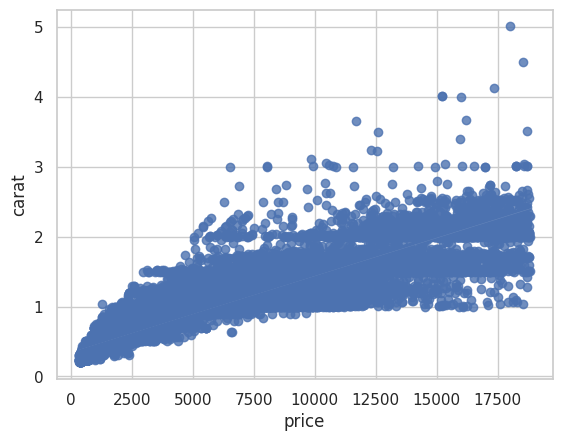

In [45]:
sns.regplot(data=df,x='price',y='carat')
plt.show()

**What I see:** the first plot (log scale) is almost a straight line, so `log_volume` explains `log_price` very well. On the normal scale (second plot) the points bend upward: when a diamond gets bigger, the price goes up faster.

## Step 5: Findings

Each finding has a number and a saved chart.

### Finding 1: Size (carat) is the biggest thing for price

Correlation of carat with price: 0.92
Correlation of volume with price: 0.92
Correlation of carat with volume: 0.999


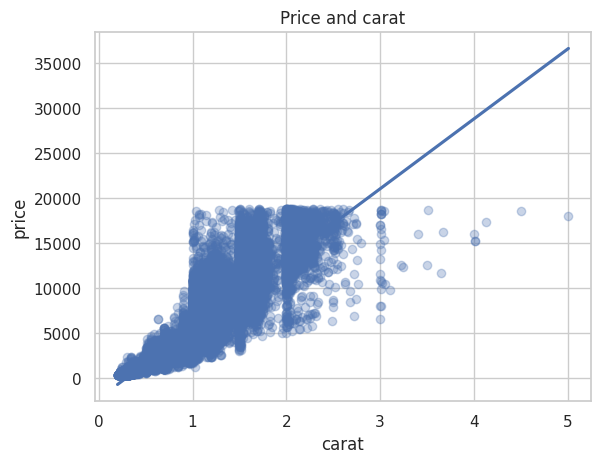

In [46]:
print("Correlation of carat with price:", round(df['carat'].corr(df['price']), 2))
print("Correlation of volume with price:", round(df['volume'].corr(df['price']), 2))
print("Correlation of carat with volume:", round(df['carat'].corr(df['volume']), 3))

sns.regplot(data=df, x='carat', y='price', ci=None, scatter_kws={'alpha': 0.3})
plt.title("Price and carat")
plt.savefig("price_by_carat.png", dpi=150, bbox_inches="tight")
plt.show()

Carat has a correlation of **0.92** with price (0.97 on the log scale). Volume gives the same result (0.92), and carat and volume are almost the same column (0.999). This means size is the main reason for the price. Bigger diamond, higher price, and the price grows faster for big diamonds.

### Finding 2: A better cut does not mean a higher average price

cut
1.0    4341.0
2.0    3916.0
3.0    3981.0
4.0    4578.0
5.0    3462.0
Name: price, dtype: float64
cut
1.0    1.04
2.0    0.85
3.0    0.81
4.0    0.89
5.0    0.70
Name: carat, dtype: float64


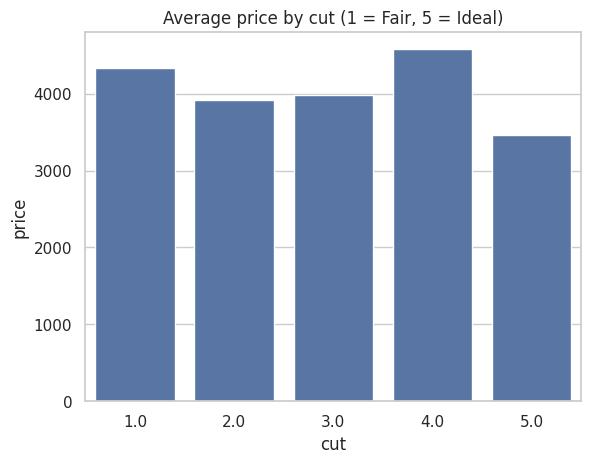

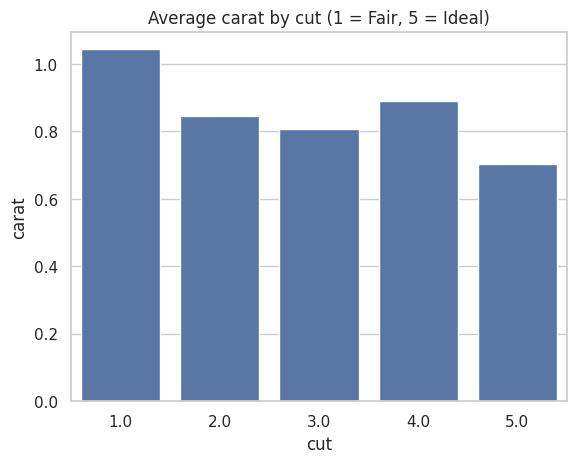

In [47]:
print(df.groupby('cut')['price'].mean().round(0))
print(df.groupby('cut')['carat'].mean().round(2))

sns.barplot(data=df, x='cut', y='price', errorbar=None)
plt.title("Average price by cut (1 = Fair, 5 = Ideal)")
plt.savefig("price_by_cut.png", dpi=150, bbox_inches="tight")
plt.show()

sns.barplot(data=df, x='cut', y='carat', errorbar=None)
plt.title("Average carat by cut (1 = Fair, 5 = Ideal)")
plt.savefig("carat_by_cut.png", dpi=150, bbox_inches="tight")
plt.show()

Ideal cut (5) has the **lowest** average price (about 3,462) and Premium (4) has the highest (about 4,578). The second chart explains why: Ideal diamonds are small (average 0.70 carat) and Fair diamonds are big (average 1.04 carat). So cut does not raise the price by itself in this data. Weight hides the effect of cut.

### Finding 3: Color and clarity show the same pattern

         price  carat
color                
1.0    5326.42   1.16
2.0    5079.84   1.02
3.0    4476.17   0.91
4.0    3999.09   0.77
5.0    3726.78   0.74
6.0    3079.82   0.66
7.0    3172.59   0.66


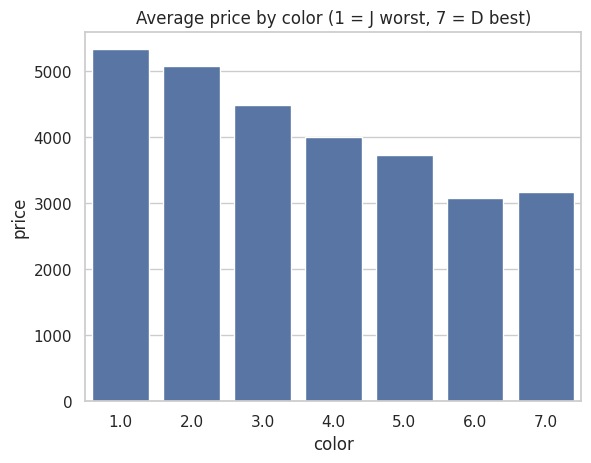

           price  carat
clarity                
1.0      3927.30   1.28
2.0      5053.75   1.08
3.0      3994.27   0.85
4.0      3925.61   0.76
5.0      3841.75   0.73
6.0      3286.53   0.60
7.0      2522.99   0.50
8.0      2870.57   0.51


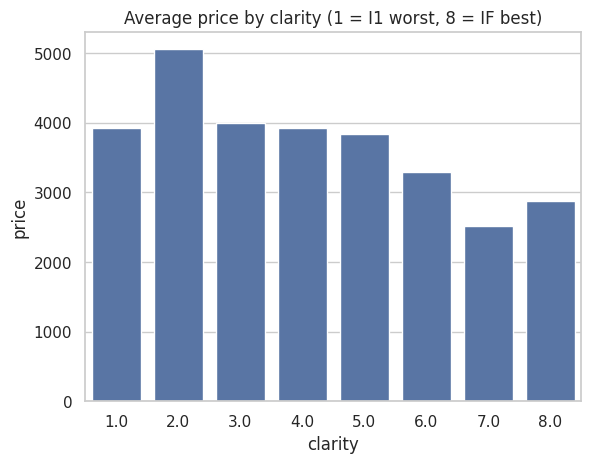

In [48]:
print(df.groupby('color')[['price', 'carat']].mean().round(2))

sns.barplot(data=df, x='color', y='price', errorbar=None)
plt.title("Average price by color (1 = J worst, 7 = D best)")
plt.savefig("price_by_color.png", dpi=150, bbox_inches="tight")
plt.show()

print(df.groupby('clarity')[['price', 'carat']].mean().round(2))

sns.barplot(data=df, x='clarity', y='price', errorbar=None)
plt.title("Average price by clarity (1 = I1 worst, 8 = IF best)")
plt.savefig("price_by_clarity.png", dpi=150, bbox_inches="tight")
plt.show()

The best color D (7) has an average price of about 3,173, but the worst color J (1) has about 5,326. For clarity, the best grade IF (8) has about 2,871 and SI2 (2) has about 5,054. Again the reason is size: color J diamonds average 1.16 carat and D only 0.66 carat, and IF diamonds average 0.51 carat. Good quality diamonds in this data are smaller, so their average price is lower.

### Finding 4: Price has a long tail and the outliers are real

Average price: 3931
Median price: 2401.0
Outliers above 11884 : 3519 (about 6.5 %)


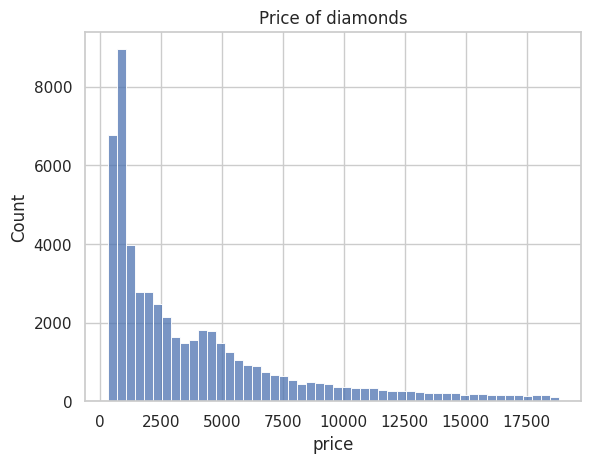

In [49]:
print("Average price:", round(df['price'].mean()))
print("Median price:", df['price'].median())
print("Outliers above", round(high), ":", len(outliers), "(about", round(len(outliers) / len(df) * 100, 1), "%)")

sns.histplot(data=df, x='price', bins=50)
plt.title("Price of diamonds")
plt.savefig("price_histogram.png", dpi=150, bbox_inches="tight")
plt.show()

Most diamonds are cheap: the median price is **2,401** but the average is **3,931**, because a few very expensive diamonds pull it up. 3,519 diamonds (**6.5%**) are above the IQR limit of 11,884. They are big (average 1.85 carat), so these are real expensive diamonds and not mistakes. This is why we kept them and used the log price for the correlations.

## Step 6: Conclusion

**What we did:** we loaded 53,940 diamonds, checked them (no missing values), cleaned the data, explored it with histograms, box plots and heatmaps, and then wrote the findings with numbers and charts.

**Main operations:**
- Removed 23 rows with wrong sizes (zero or impossible `x`, `y`, `z`) and 145 duplicate rows. Final data: 53,772 rows.
- Made `volume` from `x`, `y`, `z`, then dropped those three columns.
- Changed `cut`, `color`, `clarity` into ordered numbers with `np.where`.
- Used the IQR rule for outliers and `np.log` to reduce the long tail of volume, price and carat.

**What we found (answers to our questions):**
1. **Carat is the main thing for price.** Correlation 0.92 (0.97 on the log scale).
2. **Cut, color and clarity do not raise the average price by themselves.** Their correlation with price is small and negative, because better quality diamonds in this data are smaller.
3. **Price has outliers (3,519 diamonds, about 6.5%).** They are big, real diamonds, so we kept them.
4. **One `volume` column is enough.** It is almost the same as carat (0.999), so we do not need `x`, `y`, `z`.

**Answer to the big question:** a diamond is expensive mostly because it is **big (high carat)**. Quality grades matter less than size in this data.